# Exercício — Classificação de Perfis Musicais com KNN

Utilize os dados do questionário **Perfil de Escuta Musical** para classificar participantes em três perfis:

- 🎧 Explorador Musical - E
- ❤️ Fã Fiel - F
- 🎯 Ouvinte Contextual - C

O KNN deverá ser implementado **sem utilizar uma biblioteca que já forneça o algoritmo KNN**.

Serão investigados:
- diferentes valores de **K**;
- diferentes medidas de distância;
- desempenho do classificador.

## Preparação das labels

As respostas Q1–Q16 são as features do modelo.

Os rótulos foram definidos a partir dos escores:

$$E=(Q1+Q2+Q3+Q4+Q5)/5$$

$$F=(Q6+Q7+Q8+Q9+Q10)/5$$

$$C=(Q11+Q12+Q13+Q14+Q15+Q16)/6$$

O maior escore determina o `label`.

**Importante:** não utilize a a classe (perfil escolhido) pelo participante como feature do KNN.

## 2. Carregando os dados

Coloque o arquivo `respostas_musicais.csv` no mesmo diretório do notebook.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns

dados = pd.read_csv("respostas_questionario_musical_100_amostras.csv")
dados.head()

,id,Q1,Q2,Q3,Q4,Q5,Q6,Q7,Q8,Q9,...,Q14,Q15,Q16,Q17,Q18,Q19,E,F,C,classe
0,1,3,3,3,2,2,2,3,3,3,...,4,4,4,83,7,5,2.6,2.8,4.17,Ouvinte Contextual
1,2,4,4,5,4,4,2,2,3,2,...,3,3,4,89,6,6,4.2,2.0,2.83,Explorador Musical
2,3,2,3,2,3,3,2,3,3,2,...,4,5,4,64,7,5,2.6,2.4,4.17,Ouvinte Contextual
3,4,5,5,4,5,3,2,2,2,2,...,3,4,4,187,5,6,4.4,2.2,3.00,Explorador Musical
4,5,3,3,4,3,4,2,3,3,3,...,3,4,3,129,6,3,3.4,2.6,2.83,Explorador Musical


In [2]:
dados.shape

(100, 24)

In [3]:
dados.isnull().sum()

id        0
Q1        0
Q2        0
Q3        0
Q4        0
Q5        0
Q6        0
Q7        0
Q8        0
Q9        0
Q10       0
Q11       0
Q12       0
Q13       0
Q14       0
Q15       0
Q16       0
Q17       0
Q18       0
Q19       0
E         0
F         0
C         0
classe    0
dtype: int64

classe
Ouvinte Contextual    34
Explorador Musical    33
Fã Fiel               33
Name: count, dtype: int64


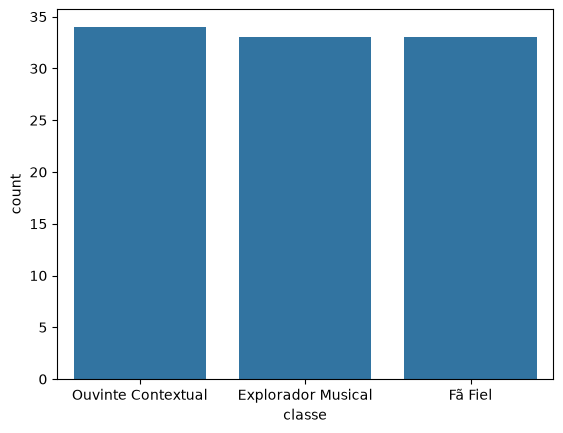

In [4]:
sns.countplot(data=dados, x='classe')
print(dados['classe'].value_counts())

### Perguntas

1. Quantas pessoas responderam?
2. Quantas colunas existem?
3. Existem valores ausentes?
4. Atribua o valor dos rótulos de classe segundo a regra acima. Quantas pessoas pertencem a cada classe?

**Responda aqui.**
1. 100 pessoas responderam
2. existem 24 colunas
3. nao existem valores nulos
4. - ouvinte contextual: 34
   - explorador musical: 33
   - fã fiel: 33

## 3. Criando X e y

Utilize Q1–Q16 como atributos e `label` como variável de saída.

In [5]:
#seu código aqui
X = dados.loc[:, "Q1":"Q16"]
y = dados.loc[:, "classe"]

print("Instâncias:", X.shape[0])
print("Atributos:", X.shape[1])
print(y.shape[0])

Instâncias: 100
Atributos: 16
100


## 4. Separação entre treinamento e validação

Utilize 70% dos dados para treinamento e 30% para validação. Faça a divisão utilizando apenas NumPy.

In [6]:
np.random.seed(42)
X = np.array(X)
y = np.array(y)

indices = np.random.permutation(len(X))
n_validacao = int(0.30 * len(X))

val_indices = indices[:n_validacao]
train_indices = indices[n_validacao:]

X_train = X[train_indices]
X_val = X[val_indices]
y_train = y[train_indices]
y_val = y[val_indices]

### Perguntas

1. Por que o conjunto de teste não deve ser usado para tomar decisões sobre o treinamento?
2. Por que é importante manter exemplos das três classes nos conjuntos?

**Responda aqui.**

1. para evitar overfitting, o conjunto de test/validacao serve para simular uma situação com novos dados reais que o modelo nunca viu
2. para garantir que o modelo aprenda padrões de todos os perfis

## 5. Distância Euclidiana

Implemente:

$$d(x,z)=\sqrt{\sum_i(x_i-z_i)^2}$$

In [7]:
def distancia_euclidiana(a, b):
    return np.sqrt(np.sum((a-b)**2))

### Teste

Compare a distância entre duas pessoas do conjunto de treinamento.

In [8]:
distancia_euclidiana(X_train[0], X_train[1])

np.float64(4.358898943540674)

### Perguntas

1. O que significa uma distância pequena entre duas pessoas?
2. O que significa uma distância grande?

**Responda aqui.**

1. que elas tem respostas/comportamentos semelhantes
2. que elas tem repostas/comportamentos muito diferentes 

## 6. Implementação do KNN

Para cada exemplo de teste:

1. calcule a distância até todos os exemplos de treinamento;
2. ordene as distâncias;
3. selecione os K vizinhos mais próximos;
4. faça uma votação majoritária.

In [9]:
def knn_predict(X_train, y_train, X_test, k=3,
                funcao_distancia=distancia_euclidiana):

    previsoes = []

    for x in X_test:
        distancias = []

        for i in range(len(X_train)):
            d = funcao_distancia(x, X_train[i])
            distancias.append((d, y_train[i]))

        distancias.sort(key=lambda item: item[0])
        vizinhos = distancias[:k]

        classes = [classe for _, classe in vizinhos]
        classes_unicas, contagens = np.unique(classes, return_counts=True)

        previsao = classes_unicas[np.argmax(contagens)]
        previsoes.append(previsao)

    return np.array(previsoes)

## 7. Primeiro experimento — K = 3

In [10]:
# seu código aqui
y_pred = knn_predict(X_train, y_train, X_val, 3)
acuracia = np.mean(y_pred == y_val)
print(f"Acurácia: {acuracia:.3f}")

Acurácia: 1.000


### Perguntas

1. Qual foi a acurácia?
2. Quantas classificações foram corretas?
3. Quantas foram incorretas?

**Responda aqui.**

1. 100%
2. 30 de 30
3. 0

## 8. Testando diferentes valores de K

Teste:

**K = 1, 3, 5, 7, 9 e 11**

Compare as acurácias.

In [11]:
valores_k = [1, 3, 5, 7, 9, 11]
resultados_k = []

#seu código aqui
for k in valores_k:
    y_pred = knn_predict(X_train, y_train, X_val, k=k)
    acc = np.mean(y_pred == y_val)
    resultados_k.append(acc)
    print(f"k={k} -> {acc:.3f}%")


k=1 -> 1.000%
k=3 -> 1.000%
k=5 -> 0.967%
k=7 -> 1.000%
k=9 -> 1.000%
k=11 -> 1.000%


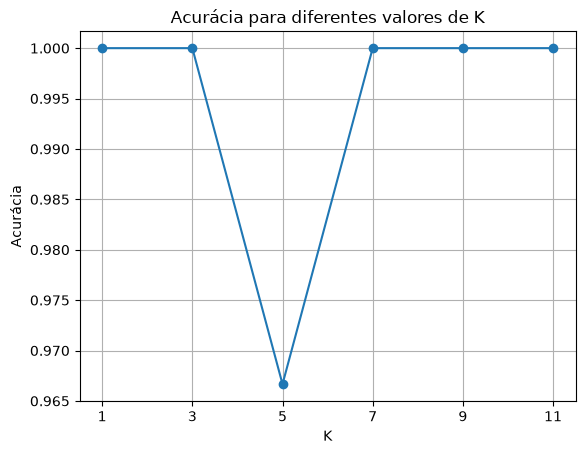

In [12]:
import matplotlib.pyplot as plt

plt.plot(valores_k, resultados_k, marker="o")
plt.xlabel("K")
plt.ylabel("Acurácia")
plt.title("Acurácia para diferentes valores de K")
plt.xticks(valores_k)
plt.grid(True)
plt.show()

### Perguntas

1. Qual K apresentou o melhor resultado?
2. O menor K foi necessariamente o melhor?
3. O maior K foi necessariamente o melhor?
4. O que pode acontecer quando K é muito pequeno?
5. O que pode acontecer quando K é muito grande?

**Responda aqui.**

1. k = 1, 3, 7, 8, 11 todos tiveram 100% de acuracia
2. nao necessariamente, aqui empatou no topo
3. nao necessariamente
4. overfitting, muito sensivel a ruido
5. modelo suaviza mais

## 9. Outras medidas de distância

Implemente:

### Manhattan

$$d(x,z)=\sum_i |x_i-z_i|$$

### Minkowski

$$d(x,z)=\left(\sum_i|x_i-z_i|^p\right)^{1/p}$$

Utilize inicialmente $p=3$.

In [13]:
def distancia_manhattan(a, b):
    return np.sum(np.abs(a-b))

In [14]:
def distancia_minkowski(a, b, p=3):
    return np.sum(np.abs(a-b)**p) ** (1/p)

### Teste

Compare as três medidas para duas instâncias.

In [15]:
a = X_train[0]
b = X_train[1]

print("Euclidiana:", distancia_euclidiana(a, b))
print("Manhattan:", distancia_manhattan(a, b))
print("Minkowski (p=3):", distancia_minkowski(a, b, p=3))

Euclidiana: 4.358898943540674
Manhattan: 13
Minkowski (p=3): 3.1413806523913927


### Perguntas

1. Os valores são iguais?
2. Por que as medidas podem produzir diferentes valores?
3. O que significa utilizar uma medida de distância diferente?

**Responda aqui.**

1. nao
2. porque metricas diferentes analisa diferencas de forma diferente, ex: para as tres que testamos: linear, quadratica e cubo
3. pode alterar quem sao os vizinhos mas proximos de um ponto, pois a geometria dessa metrica é diferente

## 10. Generalizando o KNN

A função `knn_predict` já permite informar a função de distância.

Exemplo:

```python
knn_predict(
    X_train, y_train, X_test,
    k=5,
    funcao_distancia=distancia_manhattan
)
```

## 11. Comparando as medidas

Utilize **K = 5** e compare:

- Euclidiana;
- Manhattan;
- Minkowski ($p=3$).

In [16]:
funcoes = {
    "Euclidiana": distancia_euclidiana,
    "Manhattan": distancia_manhattan,
    "Minkowski (p=3)": lambda a, b: distancia_minkowski(a, b, p=3)
}

for nome, funcao in funcoes.items():
    y_pred = knn_predict(X_train, y_train, X_val, k=5, funcao_distancia=funcao)
    acc = np.mean(y_pred == y_val)
    print(f"{nome:16s}: Acurácia = {acc:.3f}")

Euclidiana      : Acurácia = 0.967
Manhattan       : Acurácia = 1.000
Minkowski (p=3) : Acurácia = 1.000


### Perguntas

1. Qual medida apresentou a maior acurácia?
2. As diferenças foram grandes?
3. Por que a medida de distância pode influenciar o resultado?


**Responda aqui.**

repondido anteriormente

## 12. Experimento completo — K × distância

Teste todas as combinações:

- K = 1, 3, 5, 7, 9, 11;
- Euclidiana;
- Manhattan;
- Minkowski ($p=3$).

Construa uma tabela com as acurácias.

In [36]:
resultados = []

for nome, funcao in funcoes.items():
    for k in valores_k:
        y_pred = knn_predict(X_train, y_train, X_val, k=k, funcao_distancia=funcao)
        acc = np.mean(y_pred == y_val)
        resultados.append([nome, k, acc])

tabela = pd.DataFrame(
    resultados,
    columns=["Distância", "K", "Acurácia"]
)

tabela

,Distância,K,Acurácia
0,Euclidiana,1,1.000000
1,Euclidiana,3,1.000000
2,Euclidiana,5,0.966667
3,Euclidiana,7,1.000000
4,Euclidiana,9,1.000000
5,Euclidiana,11,1.000000
6,Manhattan,1,0.966667
7,Manhattan,3,1.000000
8,Manhattan,5,1.000000
9,Manhattan,7,1.000000


In [18]:
tabela_pivot = tabela.pivot(
    index="Distância",
    columns="K",
    values="Acurácia"
)

tabela_pivot

K,1,3,5,7,9,11
Distância,,,,,,
Euclidiana,1.000000,1.0,0.966667,1.0,1.0,1.0
Manhattan,0.966667,1.0,1.000000,1.0,1.0,1.0
Minkowski (p=3),0.966667,1.0,1.000000,1.0,1.0,1.0


### Perguntas

1. Qual combinação de distância e K apresentou a melhor acurácia?
2. Qual apresentou a pior?
3. O melhor K foi o mesmo para todas as distâncias?
4. A escolha da distância parece relevante?
5. O aumento de K sempre melhora o resultado?

**Responda aqui.**

praticamente todas as combinações atingiram entre 97% e 100%

nao teve grande impacto, possivelmente porque os 3 grupos estao bem separados no espaco das features

Agora utilize os melhores parâmetros no conjunto de dados coletado na aula.

## Preparação das labels

As respostas Q1–Q16 são as features do modelo.

Os rótulos foram definidos a partir dos escores:

$$E=(Q1+Q2+Q3+Q4+Q5)/5$$

$$F=(Q6+Q7+Q8+Q9+Q10)/5$$

$$C=(Q11+Q12+Q13+Q14+Q15+Q16)/6$$

O maior escore determina o `label`. Utilize essa regra para calcular a label do conjunto de teste.

**Importante:** não utilize a a classe (perfil escolhido) pelo participante como feature do KNN.

In [19]:
data = pd.read_csv("Perfil de Escuta Musical (respostas) - Respostas ao formulário 1.csv")
data.head()

,Carimbo de data/hora,Com que frequencia voce procura intencionalmente musicas que ainda nao conhece?,Com que frequencia voce experimenta um genero musical que normalmente nao escuta?,Com que frequencia voce descobre um artista novo e passa a ouvir suas musicas?,"Com que frequencia voce utiliza recomendacoes do Spotify, YouTube ou outros servicos para descobrir musicas?",Com que frequencia voce procura playlists ou selecoes de musicas novas?,Com que frequencia voce escuta novamente uma musica porque gosta muito dela?,Com que frequencia voce volta a ouvir os mesmos artistas durante varias semanas?,Com que frequencia voce adiciona uma musica de que gostou as suas playlists favoritas?,Com que frequencia voce prefere ouvir musicas que ja conhece em vez de experimentar musicas novas?,Com que frequencia voce escuta musicas de um grupo relativamente pequeno de artistas favoritos?,Com que frequencia voce escolhe musicas diferentes dependendo da atividade que esta realizando?,Com que frequencia voce utiliza musicas ou playlists especificas para estudar ou trabalhar?,Com que frequencia voce utiliza musicas ou playlists especificas para praticar exercicios?,Com que frequencia voce escolhe musicas diferentes para momentos de relaxamento?,Com que frequencia seu tipo de musica varia de acordo com seu humor?,Com que frequencia voce escolhe musicas diferentes para viagens ou deslocamentos?,Aproximadamente quantos minutos por dia voce escuta musica? (Digite apenas um número),Em quantos dias da semana voce costuma ouvir musica?,"Em quantas situacoes diferentes voce costuma ouvir musica? Considere situações como estudar, trabalhar, praticar exercícios, viajar, cozinhar, relaxar etc. (Digite apenas um número)"
0,04/09/2026 08:34:36,4,5,4,4,5,5,5.0,5,4,4,4.0,4,4,4,4,4,120,7,5
1,04/09/2026 08:34:40,4,2,3,1,1,5,5.0,5,4,4,5.0,5,5,5,1,5,no mínimo 10 minutos,5,em quase todas as situações
2,04/09/2026 08:35:26,4,3,4,5,3,5,NaN,5,5,2,NaN,4,5,3,5,3,80,7,10
3,04/09/2026 08:36:14,3,2,2,3,3,5,5.0,5,5,4,4.0,1,5,3,4,5,67,7,"praticar exercícios, relaxar, cozinhar"
4,04/09/2026 08:37:49,4,2,3,5,3,5,5.0,5,3,5,3.0,4,5,1,2,1,180,7,5


In [20]:
data.columns = ['data_hora'] + [f"Q{i}" for i in range(1, 20)]
data.head()

,data_hora,Q1,Q2,Q3,Q4,Q5,Q6,Q7,Q8,Q9,Q10,Q11,Q12,Q13,Q14,Q15,Q16,Q17,Q18,Q19
0,04/09/2026 08:34:36,4,5,4,4,5,5,5.0,5,4,4,4.0,4,4,4,4,4,120,7,5
1,04/09/2026 08:34:40,4,2,3,1,1,5,5.0,5,4,4,5.0,5,5,5,1,5,no mínimo 10 minutos,5,em quase todas as situações
2,04/09/2026 08:35:26,4,3,4,5,3,5,NaN,5,5,2,NaN,4,5,3,5,3,80,7,10
3,04/09/2026 08:36:14,3,2,2,3,3,5,5.0,5,5,4,4.0,1,5,3,4,5,67,7,"praticar exercícios, relaxar, cozinhar"
4,04/09/2026 08:37:49,4,2,3,5,3,5,5.0,5,3,5,3.0,4,5,1,2,1,180,7,5


In [27]:
for i in range (1,20):
    col = f"Q{i}"
    data[col] = pd.to_numeric(data[col], errors="coerce")

data = data.fillna(data.median(numeric_only=True))

In [28]:
def calc_label(e, f, c):
    if e >= f and e >= c: 
        return "Explorador Musical"
    elif f >= e and f >= c:
        return "Fã Fiel"
    else:
        return "Ouvinte Contextual"

In [29]:
E = data[["Q1", "Q2", "Q3", "Q4", "Q5"]].T.mean()
F = data[["Q6", "Q7", "Q8", "Q9", "Q10"]].T.mean()
C = data[["Q11", "Q12", "Q13", "Q14", "Q15", "Q16"]].T.mean()

In [30]:
labels = []
for i in range(len(data)):
    labels.append(calc_label(E[i], F[i], C[i]))
y = np.array(labels)
print(y[:5])

['Fã Fiel' 'Fã Fiel' 'Fã Fiel' 'Fã Fiel' 'Fã Fiel']


In [31]:
X_raw = data.loc[:, "Q1":"Q19"]

X_norm = (X_raw - X_raw.min()) / (X_raw.max() - X_raw.min())
X_norm = np.array(X_norm)

In [32]:
np.random.seed(42)
indices = np.random.permutation(len(X_norm))
n_val = int(0.3*len(X_norm))

val_idx = indices[:n_val]
train_idx = indices[n_val:]

In [33]:
X_train_norm = X_norm[train_idx]
X_val_norm = X_norm[val_idx]
y_train_norm = y[train_idx]
y_val_norm = y[val_idx]

In [34]:
resultados_norm = []
for nome in funcoes:
    funcao = funcoes[nome]
    for k in valores_k:
        y_pred = knn_predict(X_train_norm, y_train_norm, X_val_norm, k=k, funcao_distancia=funcao)
        acuracia = np.mean(y_pred == y_val_norm)
        resultados_norm.append([nome, k, acuracia])

In [35]:
resultados_norm

[['Euclidiana', 1, np.float64(0.75)],
 ['Euclidiana', 3, np.float64(0.75)],
 ['Euclidiana', 5, np.float64(0.75)],
 ['Euclidiana', 7, np.float64(1.0)],
 ['Euclidiana', 9, np.float64(1.0)],
 ['Euclidiana', 11, np.float64(1.0)],
 ['Manhattan', 1, np.float64(0.75)],
 ['Manhattan', 3, np.float64(0.75)],
 ['Manhattan', 5, np.float64(0.75)],
 ['Manhattan', 7, np.float64(1.0)],
 ['Manhattan', 9, np.float64(1.0)],
 ['Manhattan', 11, np.float64(1.0)],
 ['Minkowski (p=3)', 1, np.float64(0.75)],
 ['Minkowski (p=3)', 3, np.float64(0.75)],
 ['Minkowski (p=3)', 5, np.float64(1.0)],
 ['Minkowski (p=3)', 7, np.float64(1.0)],
 ['Minkowski (p=3)', 9, np.float64(1.0)],
 ['Minkowski (p=3)', 11, np.float64(1.0)]]

# Conclusão
 - acuracia entre 75% e 100% com k>=7 atigindo 100% em todas as metricas
 - provavelmente sem a normalizacao iria ser ruim pois a Q17 iria dominar, tinha valores com até 187
 - depois da normalizacao todas as variaveis passam a ter a mesma importancia